# 02 · Моделювання
### Revenue Forecast 7D

**Ціль:** для кожного нового користувача оцінити очікувану виручку за 7 днів, знаючи лише параметри реєстрації та дії за перший день.

## План
1. Спочатку рахую прості baseline-и: модель має бути кращою за них.
2. Будую двоетапну модель: класифікатор (чи заплатить) + регресор (скільки заплатить).
3. Будую одну модель з Tweedie-функцією втрат і порівнюю її з двоетапною.
4. Оцінюю моделі за користувачами та за когортами (каналами), дивлюсь калібрування й SHAP.

## Чому Tweedie
Виручка — це суми платежів: багато нулів і рідкісні великі значення. Розподіл Tweedie з параметром `ρ` між 1 і 2 описує саме такі дані (сума випадкової кількості платежів випадкового розміру).
Одна модель з таким лоссом сама враховує і нулі, і суми та одразу прогнозує середню виручку `E[y]`, яку можна сумувати по когортах. Не потрібно навчати два алгоритми й перемножувати їхні відповіді.

## Метрики
| Метрика | Навіщо |
|---|---|
| **MAE, RMSE** | Помилка в доларах на користувача. Ніколи не дивлюсь на них самі: при 98% нулів «усім 0» дає непоганий MAE |
| **Bias, %** | Наскільки сумарний прогноз відрізняється від реальної суми виручки |
| **Gini** | Якість ранжування: чи ставить модель майбутніх платників вище за решту (1 — ідеально, 0 — випадково) |
| **Top-5% share** | Яку частку реальної виручки містять 5% користувачів з найвищим прогнозом |
| **WAPE по когортах** | Загальна відносна помилка сумарної виручки по каналах. Маркетинг оцінює канали, а не окремих людей |
| **ROC-AUC, PR-AUC** | Тільки для класифікатора «чи заплатить». PR-AUC інформативніший при 2% платників |

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(str(Path.cwd().parent))
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.3f}".format

DATA_DIR = Path("../data")

import lightgbm as lgb
import shap
from lightgbm import LGBMClassifier, LGBMRegressor

from src.features import prepare_data, TARGET
from src.metrics import evaluate, gini, cohort_report
from sklearn.metrics import roc_auc_score, average_precision_score

SEED = 42

## 1. Дані та розбиття за часом
Користувачі впорядковані за часом реєстрації: найраніші 60% — **train**, наступні 20% — **valid** (для зупинки навчання та вибору `ρ`), останні 20% — **test**.
Перемішувати дані не можна: модель не повинна бачити майбутнє. Рідкісні значення `country`, `device_brand`, `device_model` (менше 200 разів у train) об'єдную в `rare`.

In [2]:
train, valid, test, FEATURES = prepare_data(DATA_DIR, min_count=200)

for name, d in [("train", train), ("valid", valid), ("test", test)]:
    print(f"{name:5s} {len(d):>9,} користувачів | {d['timestamp_reg'].min():%Y-%m-%d} → {d['timestamp_reg'].max():%Y-%m-%d} "
          f"| платників {d[TARGET].gt(0).mean():.2%} | ARPU ${d[TARGET].mean():.3f}")

print(f"\nОзнак: {len(FEATURES)}")

X_train, y_train = train[FEATURES], train[TARGET]
X_valid, y_valid = valid[FEATURES], valid[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

train   968,520 користувачів | 2024-08-01 → 2024-10-07 | платників 2.21% | ARPU $1.134
valid   322,840 користувачів | 2024-10-07 → 2024-10-29 | платників 2.06% | ARPU $1.172
test    322,840 користувачів | 2024-10-29 → 2024-11-19 | платників 1.95% | ARPU $1.058

Ознак: 27


## 2. Baseline-и
- **Усім 0** — найпростіший прогноз при 98% нулів;
- **ARPU каналу** — середня виручка `traffic_group_id` у train (так зробив би аналітик у Excel);
- **День 1 = тиждень** — прогноз дорівнює сумі оплат за перший день.

In [3]:
results = []        # таблиця метрик
predictions = {}    # прогнози кожної моделі на test

def add_result(name, pred):
    predictions[name] = np.asarray(pred, dtype=float)
    results.append(evaluate(y_test, predictions[name], name))

add_result("Baseline: усім 0", np.zeros(len(y_test)))

arpu_by_channel = train.groupby("traffic_group_id", observed=True)[TARGET].mean()
add_result("Baseline: ARPU каналу", test["traffic_group_id"].map(arpu_by_channel).astype(float).fillna(y_train.mean()))

add_result("Baseline: день 1 = тиждень", test["d1_sum_payments"])

display(pd.DataFrame(results))

,MAE,RMSE,"Bias, %",Gini,Top-5% share
Baseline: усім 0,1.058,27.287,-100.000,0.010,0.056
Baseline: ARPU каналу,2.114,27.260,4.771,0.304,0.096
Baseline: день 1 = тиждень,0.657,20.914,-59.936,0.811,0.821


**Що видно.**
- «Усім 0» має MAE $1,06, а Gini = 0,01, тобто модель нічого не знає. Це підтверджує, що MAE сам по собі нічого не каже.
- «ARPU каналу» майже точно вгадує сумарну виручку (bias +4,8%), але не вміє розрізняти людей (Gini 0,30) і має найгірший MAE (2,11): роздає середню суму всім.
- «День 1 = тиждень» добре ранжує (Gini 0,81, Top-5% share 0,82), але недооцінює виручку на 60%: у день 1 вже відомо лише частину тижня.

Мої моделі мають перевершити Gini 0,81 і не відставати від ARPU каналу за сумарною виручкою.

## 3. Двоетапна модель (класифікатор × регресор)
- **Стадія 1.** Класифікатор оцінює ймовірність, що користувач заплатить.
- **Стадія 2.** Регресор з лоссом `gamma` навчаю лише на платниках: він оцінює суму, якщо людина заплатить.
- Прогноз = ймовірність × сума.

Кількість дерев визначає early stopping по valid: навчання зупиняється, коли якість на valid не покращується 100 ітерацій.

In [4]:
# Стадія 1: чи заплатить
clf = LGBMClassifier(
    n_estimators=2000, learning_rate=0.05, num_leaves=31, min_child_samples=100,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    cat_smooth=20, min_data_per_group=100, random_state=SEED, n_jobs=-1, verbose=-1)
clf.fit(X_train, y_train.gt(0).astype(int),
        eval_set=[(X_valid, y_valid.gt(0).astype(int))], eval_metric="auc",
        callbacks=[lgb.early_stopping(100, verbose=False)])

# Стадія 2: скільки заплатить (лише платники)
paid_train = y_train.gt(0).values
paid_valid = y_valid.gt(0).values

reg = LGBMRegressor(
    objective="gamma", n_estimators=2000, learning_rate=0.05, num_leaves=31, min_child_samples=30,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    cat_smooth=20, min_data_per_group=100, random_state=SEED, n_jobs=-1, verbose=-1)
reg.fit(X_train[paid_train], y_train[paid_train],
        eval_set=[(X_valid[paid_valid], y_valid[paid_valid])],
        callbacks=[lgb.early_stopping(100, verbose=False)])

p_pay = clf.predict_proba(X_test)[:, 1]
amount_if_pay = reg.predict(X_test)
add_result("Двоетапна (клас. × регр.)", p_pay * amount_if_pay)

print(f"Дерев у класифікаторі: {clf.best_iteration_}, у регресорі: {reg.best_iteration_}")

Дерев у класифікаторі: 127, у регресорі: 31


## 4. Одна модель: LightGBM з Tweedie
Параметр `ρ` (`tweedie_variance_power`) — від 1 до 2. Значення на valid порівнювати між різними `ρ` за самим лоссом не можна, тому для вибору `ρ` я дивлюсь на Gini, MAE та bias на valid.

In [5]:
rho_values = [1.2, 1.4, 1.6, 1.8]
tweedie_models = {}
rows = []

for rho in rho_values:
    model = LGBMRegressor(
        objective="tweedie", tweedie_variance_power=rho, metric="tweedie",
        n_estimators=3000, learning_rate=0.05, num_leaves=31, min_child_samples=100,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
        cat_smooth=20, min_data_per_group=100, random_state=SEED, n_jobs=-1, verbose=-1)
    model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)],
              callbacks=[lgb.early_stopping(100, verbose=False)])
    pred = model.predict(X_valid)

    tweedie_models[rho] = model
    rows.append({"rho": rho, "trees": model.best_iteration_,
                 "valid_Gini": gini(y_valid, pred),
                 "valid_MAE": np.abs(pred - y_valid).mean(),
                 "valid_bias_%": 100 * (pred.sum() - y_valid.sum()) / y_valid.sum()})

rho_table = pd.DataFrame(rows).set_index("rho")
display(rho_table)

,trees,valid_Gini,valid_MAE,valid_bias_%
rho,,,,
1.200,71,0.938,1.074,-16.408
1.400,58,0.941,1.029,-40.175
1.600,46,0.944,1.145,-68.269
1.800,24,0.941,1.252,-82.455


Gini майже не змінюється між `ρ` (0,938–0,944), а зсув сумарної виручки змінюється сильно: від −16% при `ρ = 1,2` до −82% при `ρ = 1,8`. Тобто чим більше `ρ`, тим сильніше модель занижує виручку.
Я обираю `ρ` за найвищим Gini; це дає `ρ = 1,6`. Але з таблиці видно, що критерій Gini не бачить зсуву, і ця проблема дається взнаки далі, на test.

In [6]:
best_rho = rho_table["valid_Gini"].idxmax()
tweedie = tweedie_models[best_rho]
print(f"Обрано ρ = {best_rho}, дерев: {tweedie.best_iteration_}")

add_result(f"LightGBM Tweedie (ρ={best_rho})", tweedie.predict(X_test))

Обрано ρ = 1.6, дерев: 46


## 5. Результати на test

In [7]:
display(pd.DataFrame(results))

print("Компонента «чи заплатить»:")
tweedie_pred = predictions[f"LightGBM Tweedie (ρ={best_rho})"]
display(pd.DataFrame({
    "ROC-AUC": [roc_auc_score(y_test > 0, p_pay), roc_auc_score(y_test > 0, tweedie_pred)],
    "PR-AUC": [average_precision_score(y_test > 0, p_pay), average_precision_score(y_test > 0, tweedie_pred)],
}, index=["Двоетапна: ймовірність", "Tweedie: прогноз як скор"]))

,MAE,RMSE,"Bias, %",Gini,Top-5% share
Baseline: усім 0,1.058,27.287,-100.000,0.010,0.056
Baseline: ARPU каналу,2.114,27.260,4.771,0.304,0.096
Baseline: день 1 = тиждень,0.657,20.914,-59.936,0.811,0.821
Двоетапна (клас. × регр.),0.995,24.163,-34.395,0.954,0.911
LightGBM Tweedie (ρ=1.6),1.032,26.340,-65.842,0.950,0.904


Компонента «чи заплатить»:


,ROC-AUC,PR-AUC
Двоетапна: ймовірність,0.955,0.802
Tweedie: прогноз як скор,0.951,0.752


**Висновки.**
- Обидві моделі ранжують користувачів значно краще за baseline «день 1 = тиждень»: Gini 0,95 проти 0,81, Top-5% share 0,90–0,91 проти 0,82.
- Двоетапна й Tweedie майже однакові за ранжуванням (Gini 0,954 та 0,950). Класифікатор окремо: ROC-AUC 0,955, PR-AUC 0,802 (для порівняння, випадкова модель має PR-AUC ≈ 0,02).
- **Але обидві занижують сумарну виручку: двоетапна на 34%, Tweedie на 66%.** Baseline «ARPU каналу» помиляється на +4,8%.
- MAE майже не відрізняє моделі від baseline «усім 0» ($1,06): $0,995 у двоетапної та $1,03 в Tweedie. Для цієї задачі MAE малоінформативний, тому я спираюсь на Gini, bias і помилки по когортах.

### 5.1 Користувачі, які не платили в день 1
Для них baseline «день 1 = тиждень» дає 0 і нічого не знає. Усе, що модель тут вгадує, походить з параметрів реєстрації та поведінки.

In [8]:
no_day1_payment = (test["d1_cnt_payments"] == 0).values
print(f"{no_day1_payment.sum():,} користувачів, платників серед них {y_test[no_day1_payment].gt(0).mean():.2%}")

subset = [evaluate(y_test[no_day1_payment], predictions[name][no_day1_payment], name) for name in predictions]
display(pd.DataFrame(subset))

318,313 користувачів, платників серед них 0.57%


,MAE,RMSE,"Bias, %",Gini,Top-5% share
Baseline: усім 0,0.200,8.020,-100.000,-0.002,0.062
Baseline: ARPU каналу,1.289,8.082,453.647,0.358,0.156
Baseline: день 1 = тиждень,0.200,8.020,-100.000,-0.002,0.062
Двоетапна (клас. × регр.),0.361,7.993,-9.725,0.774,0.580
LightGBM Tweedie (ρ=1.6),0.328,7.998,-28.888,0.758,0.551


**Висновки.** Серед 318 313 користувачів без оплат у день 1 платників лише 0,57%.
- «Усім 0» тут має найменший MAE (0,20), краще за обидві моделі (0,33–0,36), бо майже всі справжні значення — нулі. Знову видно, що MAE вводить в оману.
- Але за ранжуванням моделі справді знаходять майбутніх платників: **Gini 0,77 (двоетапна) і 0,76 (Tweedie)** проти 0 в «усім 0» та «день 1 = тиждень». Топ-5% за прогнозом містять 58% і 55% виручки цієї групи.
- У цій групі зсув менший: −9,7% (двоетапна) і −28,9% (Tweedie). Baseline «ARPU каналу» тут дає +454%: він роздає середню суму всім.

### 5.2 Помилка по когортах
Маркетинг оцінює канали, тому порівнюю реальну й прогнозовану сумарну виручку по каналах (`traffic_group_id`) та по зв'язці тип трафіку × тиждень реєстрації. WAPE — загальна відносна помилка по всіх когортах (враховую когорти з 500+ користувачів).

In [9]:
test["reg_week"] = test["timestamp_reg"].dt.tz_localize(None).dt.to_period("W").astype(str)
models_to_compare = ["Baseline: ARPU каналу", "Baseline: день 1 = тиждень",
                     "Двоетапна (клас. × регр.)", f"LightGBM Tweedie (ρ={best_rho})"]

for by in ["traffic_group_id", ["traffic_type_id", "reg_week"]]:
    print("Когорти:", by)
    wape = {name: cohort_report(test, predictions[name], by)[1] for name in models_to_compare}
    display(pd.Series(wape, name="WAPE, %").to_frame())

table, _ = cohort_report(test, predictions[f"LightGBM Tweedie (ρ={best_rho})"], "traffic_group_id")
print("Найбільші канали, Tweedie:")
display(table.sort_values("actual", ascending=False).head(10))

Когорти: traffic_group_id


,"WAPE, %"
Baseline: ARPU каналу,18.131
Baseline: день 1 = тиждень,59.936
Двоетапна (клас. × регр.),34.395
LightGBM Tweedie (ρ=1.6),65.842


Когорти: ['traffic_type_id', 'reg_week']


,"WAPE, %"
Baseline: ARPU каналу,13.715
Baseline: день 1 = тиждень,59.936
Двоетапна (клас. × регр.),34.395
LightGBM Tweedie (ρ=1.6),65.842


Найбільші канали, Tweedie:


,users,actual,pred,error_%
traffic_group_id,,,,
5,33433,"67,239.850","21,194.838",-68.479
6,29858,"50,986.340","13,290.162",-73.934
3,35564,"50,364.730","20,638.311",-59.022
1,122656,"47,393.790","18,772.140",-60.391
8,22962,"31,964.360","10,713.108",-66.484
4,20924,"20,108.140","6,138.394",-69.473
10,4333,"17,075.210","3,655.981",-78.589
2,13231,"16,674.560","5,675.117",-65.965
7,13435,"16,120.110","6,407.208",-60.253


**Висновки.**
- WAPE по каналах: ARPU каналу — **18,1%**, двоетапна — 34,4%, день 1 = тиждень — 59,9%, Tweedie — 65,8%. По типу трафіку × тижню ARPU каналу ще точніший (13,7%).
- Прості «ARPU каналу» виграють у обох моделей, бо моделі системно занижують виручку. В усіх десяти найбільших каналах Tweedie недооцінює виручку на 58–79%. Помилка однакова скрізь, а це означає, що проблема в загальному рівні прогнозу, а не в окремих каналах.

### 5.3 Калібрування
Ділю користувачів test на 20 груп за прогнозом і порівнюю середній прогноз із середнім фактом. Якщо модель калібрована, точки лежать на діагоналі.

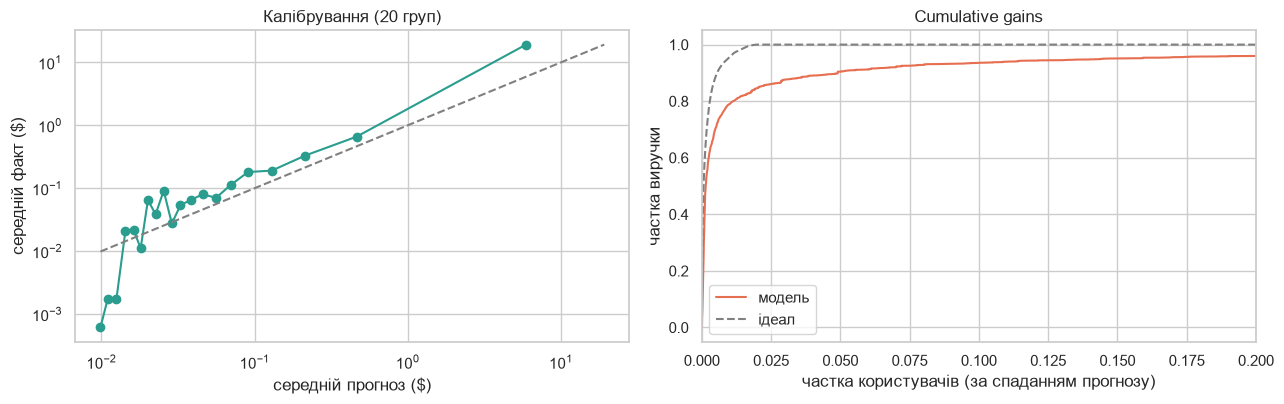

In [10]:
calib = pd.DataFrame({"actual": y_test.values, "pred": tweedie_pred})
calib["group"] = pd.qcut(calib["pred"].rank(method="first"), 20, labels=False)
calib = calib.groupby("group")[["pred", "actual"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

axes[0].plot(calib["pred"], calib["actual"], "o-", color="#2a9d8f")
line = [calib["pred"].min(), calib[["pred", "actual"]].max().max()]
axes[0].plot(line, line, "--", color="grey")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("середній прогноз ($)")
axes[0].set_ylabel("середній факт ($)")
axes[0].set_title("Калібрування (20 груп)")

order = np.argsort(-tweedie_pred)
gain = np.cumsum(y_test.values[order]) / y_test.sum()
ideal = np.cumsum(np.sort(y_test.values)[::-1]) / y_test.sum()
share = np.arange(1, len(gain) + 1) / len(gain)
axes[1].plot(share, gain, color="#e76f51", label="модель")
axes[1].plot(share, ideal, "--", color="grey", label="ідеал")
axes[1].set_xlim(0, 0.2)
axes[1].set_xlabel("частка користувачів (за спаданням прогнозу)")
axes[1].set_ylabel("частка виручки")
axes[1].set_title("Cumulative gains")
axes[1].legend()
plt.tight_layout()
plt.show()

**Висновки.** Більшість точок (крім кількох груп із найменшими прогнозами) лежать вище діагоналі, тобто модель занижує виручку майже по всьому діапазону. Найсильніше в групі з найвищим прогнозом: середній факт близько 20, а середній прогноз — близько 6, приблизно у три рази менше. Це «кити», на яких припадає основна виручка.
Кумулятивна крива показує, що модель добре ставить платників угору: перші 5% за прогнозом містять приблизно 90% виручки. Тобто проблема не в ранжуванні, а у величині прогнозу.

## 6. Інтерпретація (SHAP)
SHAP показує, як кожна ознака зсуває прогноз. Tweedie працює з логарифмом очікуваної виручки, тому значення SHAP — це вплив на `log E[y]`. Чим правіше точка, тим більше ця ознака збільшує прогноз.
Пояснюю LightGBM Tweedie: ранжування в усіх моделей однакове (Gini ≈ 0,95), тож я очікую подібний набір ключових ознак.

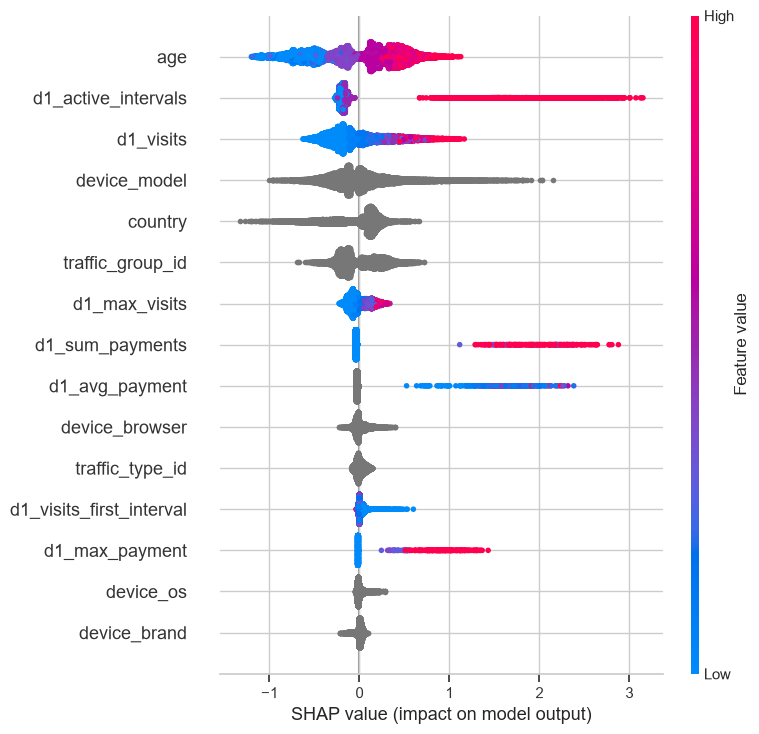

,mean |SHAP|
age,0.409
d1_active_intervals,0.326
d1_visits,0.267
device_model,0.252
country,0.198
traffic_group_id,0.189
d1_max_visits,0.094
d1_sum_payments,0.066
d1_avg_payment,0.050
device_browser,0.049


In [11]:
sample = X_test.sample(n=20000, random_state=SEED)
shap_values = shap.TreeExplainer(tweedie).shap_values(sample)

shap.summary_plot(shap_values, sample, max_display=15)

importance = pd.Series(np.abs(shap_values).mean(axis=0), index=sample.columns).sort_values(ascending=False)
display(importance.head(12).to_frame("mean |SHAP|"))

**Висновки.**
- Найбільший середній внесок у `log E[y]` у ознак **`age` (0,41)**, `d1_active_intervals` (0,33), `d1_visits` (0,27), `device_model` (0,25) та `country` (0,20); далі `traffic_group_id` (0,19).
- **`d1_active_intervals`** (у скількох 6-годинних інтервалах були візити): високі значення збільшують прогноз найсильніше, SHAP до +3, тобто прогноз може зростати більш ніж у 20 разів. Так само діють `d1_visits` та оплати першого дня (`d1_sum_payments`: SHAP від +1 до +3).
- **`age`**: старші користувачі мають вищий прогноз, молодші нижчий. Кореляція віку з таргетом майже нульова (≈0,04), тож зв'язок нелінійний або проявляється лише разом з іншими ознаками. Я не перевіряв його окремо, тому не роблю висновків про причини.
- `device_model`, `country` і `traffic_group_id` мають великий розкид впливу, тобто частина відмінностей між користувачами пояснюється каналом, країною й пристроєм.
- Важливість усереднена по всіх користувачах, тому ознаки, що розрізняють різні рівні дуже малих прогнозів (як `age`), можуть виглядати важливішими, ніж для самих платників.

## Проміжний висновок
- Обидві моделі добре ранжують (Gini 0,95; на користувачах без оплат у день 1 — 0,76–0,77), що значно краще за baseline-и.
- Але LightGBM Tweedie занижує сумарну виручку на 66%, а двоетапна на 34%, і через це по каналах вони програють простому «ARPU каналу» (WAPE 65,8% і 34,4% проти 18,1%).
- Занижується насамперед виручка від «китів».

У `03_model_comparison` перевіряю, чи залежить зсув від бібліотеки: беру XGBoost і CatBoost з тим самим Tweedie-лоссом.